# Khám phá dữ liệu HPG (EDA)

Notebook phân tích bộ dữ liệu HPG đã ghép sẵn. `target_volatility_5d` là độ lệch chuẩn của lợi suất trong **5 phiên kế tiếp**, được dùng làm nhãn dự báo và không dùng làm đặc trưng đầu vào tại thời điểm hiện tại.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
# Font hỗ trợ tiếng Việt; Matplotlib tự tìm font khả dụng theo danh sách này.
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "DejaVu Sans", "Liberation Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.figsize"] = (12, 5)
DATA_DIR = Path("../data")  # Notebook chạy từ thư mục notebooks


In [2]:
raw_hpg = pd.read_csv(DATA_DIR / "raw" / "hpg.csv")
hpg = pd.read_csv(DATA_DIR / "processed" / "hpg_features_target_5d.csv", parse_dates=["date"])
hpg = hpg.sort_values("date").reset_index(drop=True)

print(f"Dữ liệu gốc: {raw_hpg.shape[0]:,} dòng × {raw_hpg.shape[1]} cột")
print(f"Dữ liệu đã xử lý: {hpg.shape[0]:,} dòng × {hpg.shape[1]} cột")
print(f"Khoảng thời gian: {hpg.date.min():%Y-%m-%d} đến {hpg.date.max():%Y-%m-%d}")
display(hpg.head())

Dữ liệu gốc: 1,781 dòng × 6 cột
Dữ liệu đã xử lý: 4,515 dòng × 24 cột
Khoảng thời gian: 2007-11-15 đến 2026-10-21


,date,open,high,low,close,volume,return_1d,return_5d,return_10d,return_20d,...,rolling_volatility_5,rolling_volatility_20,volume_change,volume_ma_20,high_low_range,open_close_range,target_volatility_5d,ticker,partition,validation_fold
0,2007-11-15,1.83,1.83,1.53,1.79,1306330,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.167598,-0.021858,3.682889,HPG,unused,NaN
1,2007-11-16,1.70,1.70,1.70,1.70,248510,-5.158737,NaN,NaN,NaN,...,NaN,NaN,-0.809765,NaN,0.000000,0.000000,3.385237,HPG,unused,NaN
2,2007-11-19,1.62,1.62,1.62,1.62,120480,-4.820210,NaN,NaN,NaN,...,NaN,NaN,-0.515191,NaN,0.000000,0.000000,2.950554,HPG,unused,NaN
3,2007-11-20,1.55,1.55,1.55,1.55,58710,-4.417122,NaN,NaN,NaN,...,NaN,NaN,-0.512699,NaN,0.000000,0.000000,2.674624,HPG,unused,NaN
4,2007-11-21,1.48,1.60,1.48,1.60,728080,3.174870,NaN,NaN,NaN,...,NaN,NaN,11.401294,NaN,0.075000,0.081081,2.243299,HPG,unused,NaN


## 1. Cấu trúc và chất lượng dữ liệu

Kiểm tra kiểu dữ liệu, ngày trùng, giá trị thiếu và các ràng buộc OHLC cơ bản. Giá được giữ theo đơn vị trong file nguồn. Các giá trị thiếu ở đầu chuỗi thường đến từ cửa sổ rolling; nhãn tương lai thiếu ở cuối chuỗi do chưa đủ dữ liệu.

In [3]:
display(pd.DataFrame({"dtype": hpg.dtypes.astype(str), "missing": hpg.isna().sum(), "missing_%": (100 * hpg.isna().mean()).round(2), "unique": hpg.nunique()}))
print("Ngày trùng:", hpg.date.duplicated().sum())
print("Ticker:", hpg.ticker.unique() if "ticker" in hpg else "không có cột ticker")
print("Giá không dương:", (hpg[["open", "high", "low", "close"]] <= 0).any(axis=1).sum())
print("OHLC sai thứ tự (low > high):", (hpg.low > hpg.high).sum())
print("Khối lượng âm:", (hpg.volume < 0).sum())

# Thiếu dữ liệu do cửa sổ rolling và horizon tương lai; không cắt theo index.
display(hpg[["return_1d", "MA_5", "MA_20", "MA_50", "rolling_volatility_5", "rolling_volatility_20", "target_volatility_5d"]].isna().sum().rename("missing_rows"))

,dtype,missing,missing_%,unique
date,datetime64[ns],0,0.00,4515
open,float64,0,0.00,1269
high,float64,0,0.00,1312
low,float64,0,0.00,1300
close,float64,0,0.00,1314
volume,int64,0,0.00,4493
return_1d,float64,1,0.02,2979
return_5d,float64,5,0.11,3449
return_10d,float64,10,0.22,3645
return_20d,float64,20,0.44,3786


Ngày trùng: 0
Ticker: ['HPG']
Giá không dương: 0
OHLC sai thứ tự (low > high): 0
Khối lượng âm: 0


return_1d                 1
MA_5                      4
MA_20                    19
MA_50                    49
rolling_volatility_5      5
rolling_volatility_20    20
target_volatility_5d      5
Name: missing_rows, dtype: int64

## 2. Diễn biến giá và thanh khoản

Giá đóng cửa thể hiện xu hướng dài hạn; khối lượng dùng trục log để quan sát cả các phiên đột biến lẫn giai đoạn thông thường. Đường trung bình động chỉ tóm tắt dữ liệu quá khứ.

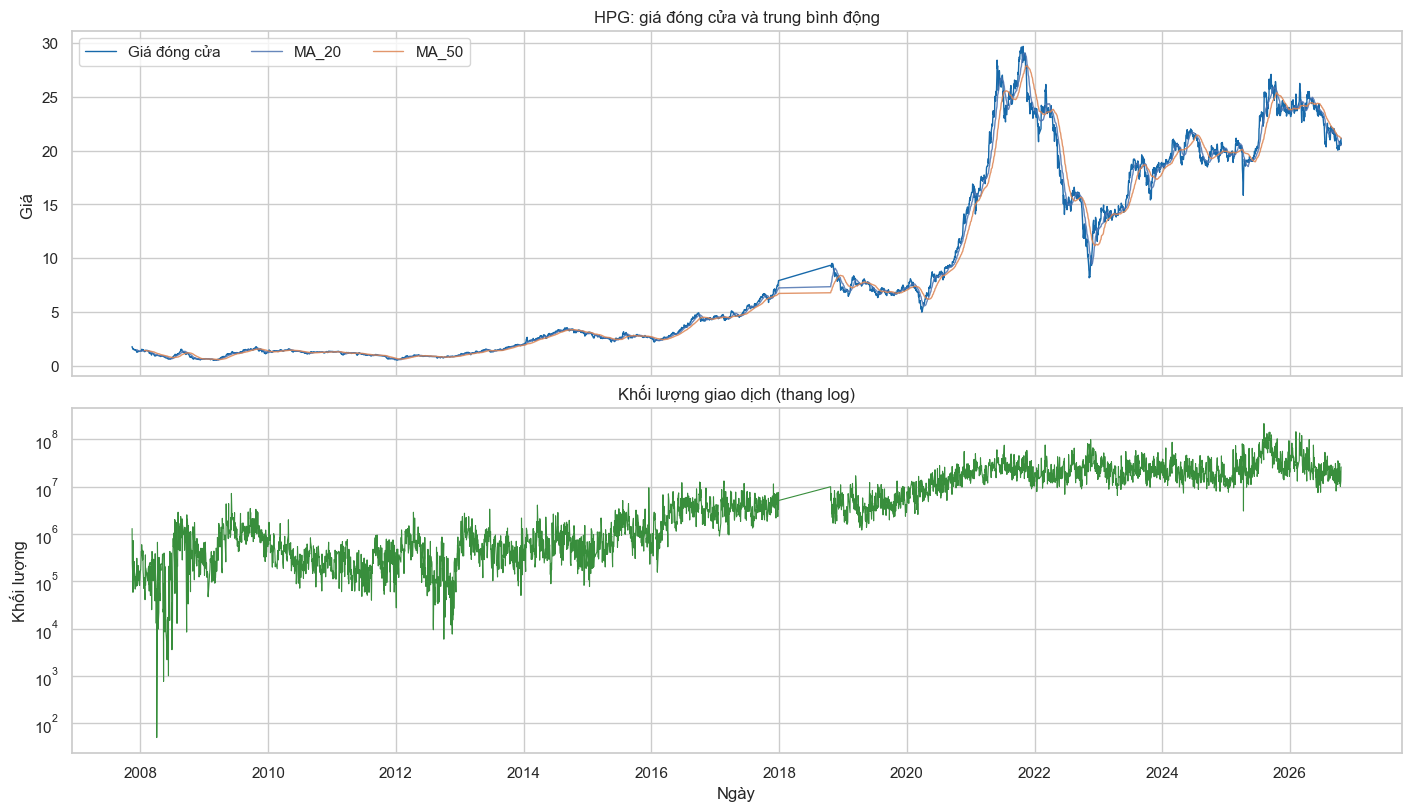

In [4]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True, layout="constrained")
ax[0].plot(hpg.date, hpg.close, color="#1769aa", lw=1, label="Giá đóng cửa")
for col, color in [("MA_20", "#ef6c00"), ("MA_50", "#7b1fa2")]:
    ax[0].plot(hpg.date, hpg[col], lw=1, alpha=.85, label=col)
ax[0].set(title="HPG: giá đóng cửa và trung bình động", ylabel="Giá ")
ax[0].legend(ncol=3)
ax[1].plot(hpg.date, hpg.volume, color="#388e3c", lw=.8)
ax[1].set_yscale("log")
ax[1].set(title="Khối lượng giao dịch (thang log)", ylabel="Khối lượng", xlabel="Ngày")
plt.show()

## 3. Lợi suất và các phiên biến động mạnh

`return_1d` là log-return tính theo phần trăm. Thống kê mô tả và các phiên cực trị giúp nhận diện phân phối lợi suất và những ngày biến động lớn.

,Lợi suất ngày (%)
count,4514.000000
mean,0.054706
std,2.218354
min,-7.472355
1%,-5.496471
5%,-3.776135
25%,-1.121483
50%,0.000000
75%,1.171661
95%,4.082199


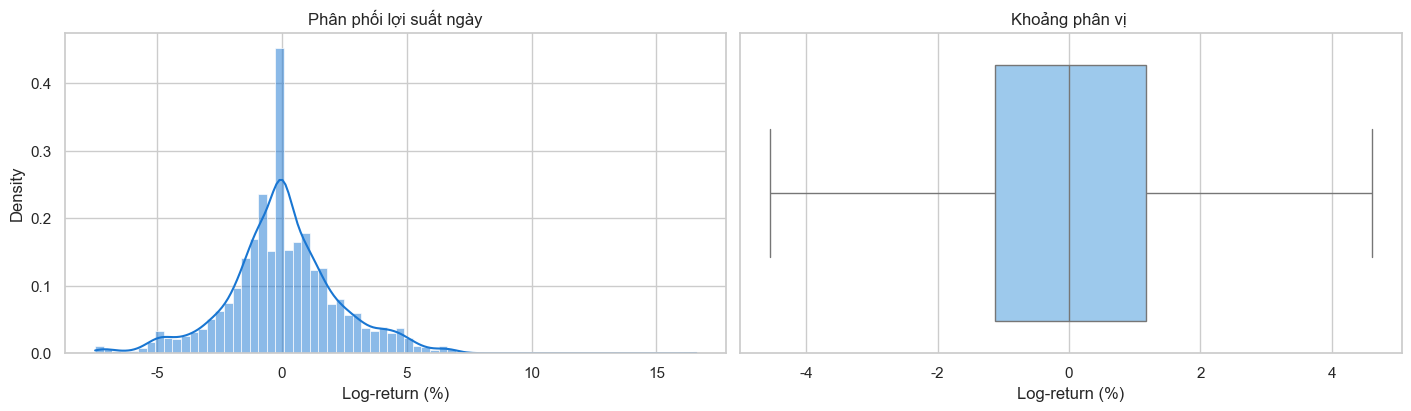

,date,open,high,low,close,volume,return_1d
1305,2013-02-21,1.25,1.28,1.16,1.16,2332340,-7.472355
1926,2015-08-24,2.63,2.63,2.50,2.50,4405860,-7.325046
3551,2022-12-06,13.46,13.49,12.58,12.58,62798971,-7.280119
1312,2013-03-04,1.14,1.14,1.06,1.06,1297130,-7.275935
4358,2026-03-09,22.76,23.35,22.63,22.63,121179573,-7.243370
4132,2025-04-09,15.85,16.59,15.85,15.85,77212228,-7.239402
2871,2020-03-23,5.36,5.54,5.33,5.33,12947170,-7.236429
4265,2025-10-20,24.91,25.22,23.26,23.26,103075157,-7.214068
3394,2022-04-25,22.42,22.42,20.86,20.86,29055100,-7.211997
2861,2020-03-09,6.42,6.63,6.42,6.42,16567350,-7.210329


In [5]:
returns = hpg.return_1d.dropna()
display(returns.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("Lợi suất ngày (%)"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
sns.histplot(returns, bins=70, stat="density", kde=True, ax=ax[0], color="#1976d2")
ax[0].set(title="Phân phối lợi suất ngày", xlabel="Log-return (%)")
sns.boxplot(x=returns, ax=ax[1], color="#90caf9", showfliers=False)
ax[1].set(title="Khoảng phân vị ", xlabel="Log-return (%)")
plt.show()
extremes = pd.concat([hpg.nsmallest(10, "return_1d"), hpg.nlargest(10, "return_1d")]).drop_duplicates().sort_values("return_1d")
display(extremes[["date", "open", "high", "low", "close", "volume", "return_1d"]])

## 4. Biến động lịch sử và nhãn dự báo

Rolling volatility được tính từ lợi suất quá khứ. Nhãn `target_volatility_5d` đo biến động **5 phiên tương lai**; tương quan trong biểu đồ chỉ mang tính mô tả, không chứng minh quan hệ nhân quả. Năm phiên cuối thiếu nhãn là điều dự kiến.

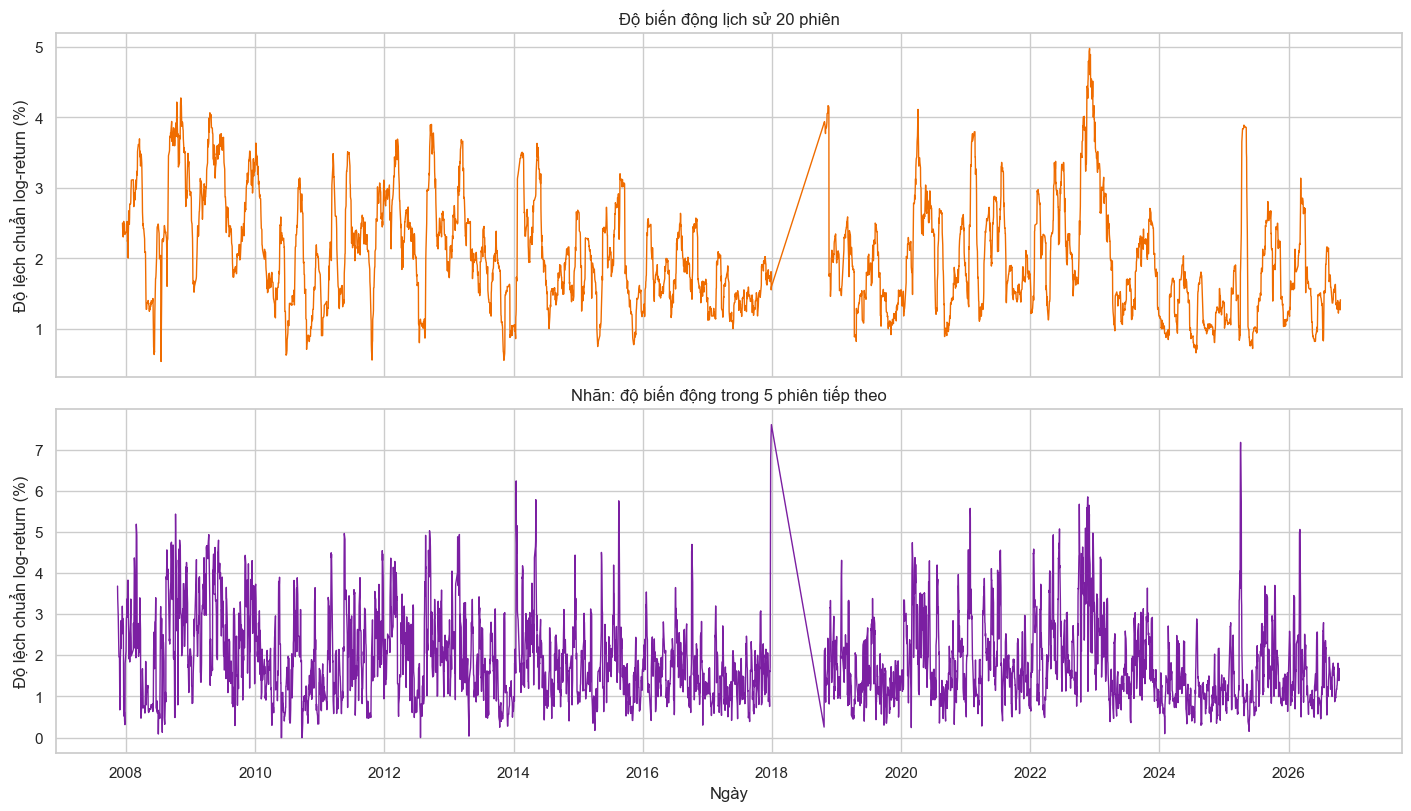

,Biến động 5 phiên tới
count,4510.000000
mean,1.894893
std,1.053030
min,0.000000
10%,0.748268
25%,1.120374
50%,1.652931
75%,2.469502
90%,3.374528
95%,3.973118


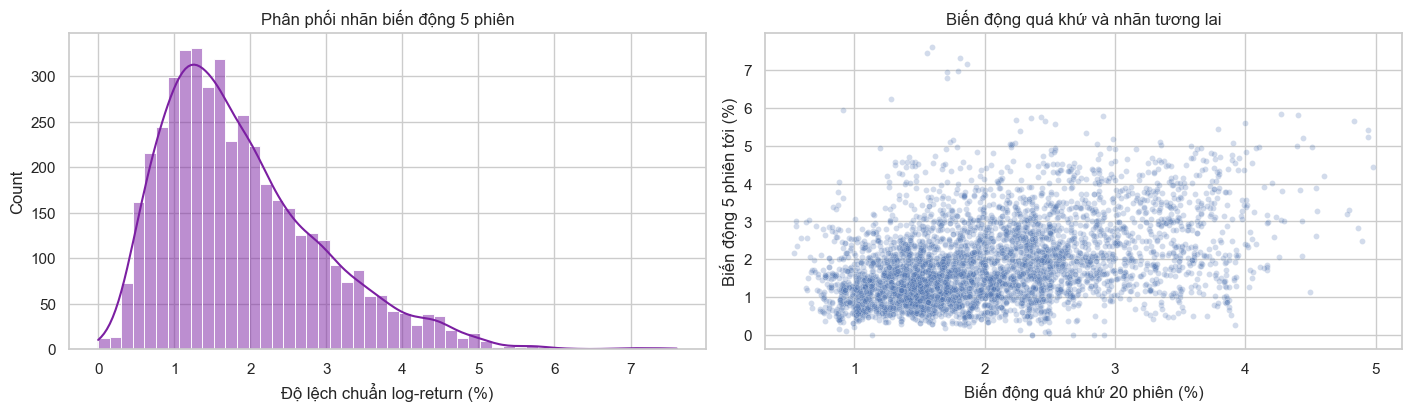

Tương quan Pearson : 0.394


In [6]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True, layout="constrained")
ax[0].plot(hpg.date, hpg.rolling_volatility_20, color="#ef6c00", lw=1)
ax[0].set(title="Độ biến động lịch sử 20 phiên", ylabel="Độ lệch chuẩn log-return (%)")
ax[1].plot(hpg.date, hpg.target_volatility_5d, color="#7b1fa2", lw=1)
ax[1].set(title="Nhãn: độ biến động trong 5 phiên tiếp theo", ylabel="Độ lệch chuẩn log-return (%)", xlabel="Ngày")
plt.show()

target = hpg.target_volatility_5d.dropna()
display(target.describe(percentiles=[.1, .25, .5, .75, .9, .95, .99]).to_frame("Biến động 5 phiên tới"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
sns.histplot(target, bins=50, kde=True, ax=ax[0], color="#7b1fa2")
ax[0].set(title="Phân phối nhãn biến động 5 phiên", xlabel="Độ lệch chuẩn log-return (%)")
sns.scatterplot(data=hpg, x="rolling_volatility_20", y="target_volatility_5d", alpha=.25, s=18, ax=ax[1])
ax[1].set(title="Biến động quá khứ và nhãn tương lai", xlabel="Biến động quá khứ 20 phiên (%)", ylabel="Biến động 5 phiên tới (%)")
plt.show()
print("Tương quan Pearson :", hpg[["rolling_volatility_20", "target_volatility_5d"]].corr().iloc[0, 1].round(3))

## 5. Tóm tắt theo năm và tương quan đặc trưng

Thống kê theo năm cho thấy các giai đoạn khác nhau về lợi suất, biến động và thanh khoản. Khi xem tương quan, loại nhãn tương lai khỏi nhóm đặc trưng; đây chỉ là bước sàng lọc ban đầu.

,sessions,close_first,close_last,mean_abs_return,mean_volatility_20,median_volume,mean_target_5d,price_change_%
year,,,,,,,,
2007,32,1.79,1.35,2.013,2.418,126575.0,2.002,-24.581
2008,245,1.36,0.66,2.616,2.763,278450.0,2.363,-51.471
2009,249,0.65,1.28,2.464,2.843,913900.0,2.739,96.923
2010,250,1.33,1.33,1.292,1.863,329425.0,1.592,0.000
2011,248,1.33,0.60,1.764,2.180,234470.0,2.057,-54.887
2012,250,0.59,1.00,1.919,2.476,264325.0,2.257,69.492
2013,250,1.00,2.02,1.470,1.993,541575.0,1.794,102.000
2014,247,2.02,3.07,1.593,2.105,581170.0,2.046,51.980
2015,248,3.07,2.60,1.420,1.896,925050.0,1.675,-15.309


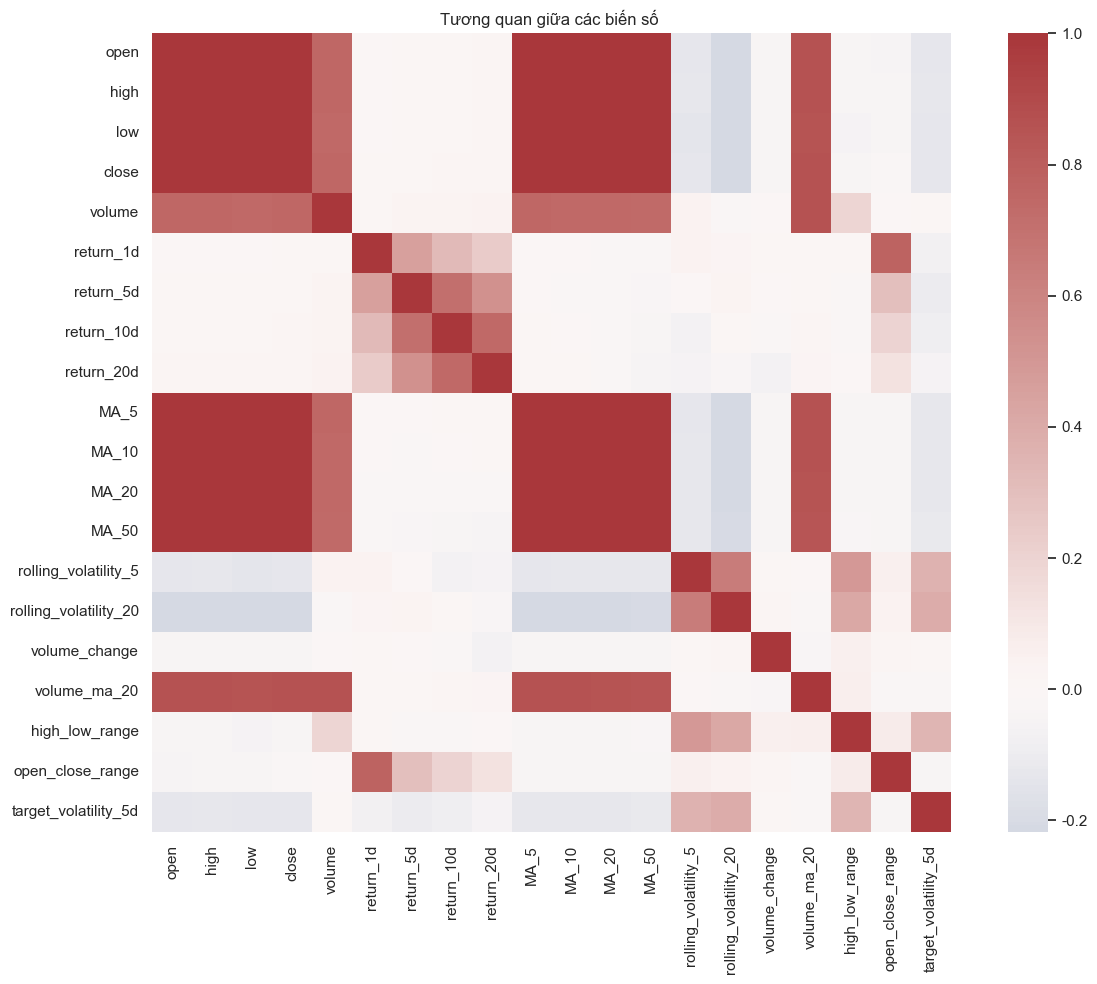

In [8]:
annual = hpg.assign(year=hpg.date.dt.year).groupby("year").agg(
    sessions=("date", "size"), close_first=("close", "first"), close_last=("close", "last"),
    mean_abs_return=("return_1d", lambda s: s.abs().mean()),
    mean_volatility_20=("rolling_volatility_20", "mean"),
    median_volume=("volume", "median"), mean_target_5d=("target_volatility_5d", "mean")
)
annual["price_change_%"] = 100 * (annual.close_last / annual.close_first - 1)
display(annual.round(3))

feature_cols = [c for c in hpg.select_dtypes(include="number").columns if c != "validation_fold"]
corr = hpg[feature_cols].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="vlag", center=0, annot=False, square=True)
plt.title("Tương quan giữa các biến số ")
plt.tight_layout()
plt.show()

## Kết luận và lưu ý cho mô hình

- Dữ liệu có 4.515 phiên HPG; giá trị thiếu đầu chuỗi chủ yếu do cửa sổ rolling, cuối chuỗi do nhãn 5 phiên tương lai.
- Không đưa `target_volatility_5d` vào tập đặc trưng `X`.
- Chia train/validation/test theo thời gian; cân nhắc cách ít nhất 5 phiên để nhãn không chồng lấn qua ranh giới.
- Đánh giá bằng backtest theo thời gian; tương quan toàn bộ dữ liệu không thay thế được kết quả ngoài mẫu.